# Phase 4 — Dynamical reconstruction and robustness evaluation

**Course:** Dynamical Systems in Machine Learning  
**Project:** Identifying Nonlinear Dynamical Systems Using Generative Recurrent Neural Networks  
**Based on:** Koppe et al. (2019), *Identifying nonlinear dynamical systems via generative recurrent neural networks with applications to fMRI*.

## Research questions

1. Does a PLRNN reconstruct the original **long-term nonlinear dynamics**, not only a few-step prediction?
2. Are results robust to **training seeds** and **initial latent states**?
3. How does a PLRNN compare with a **latent-dimension-matched LDS**?
4. How does increasing **observation noise** change forecasting and long-run reproduction?

We report **every** restart rather than select the most visually appealing model. These experiments assess a **simplified MAP PLRNN**, not the full Laplace-EM of the paper.

## 1. Mathematical model and evaluation criteria

The PLRNN state equations are

$$
\mathbf{z}_t=A\mathbf{z}_{t-1}+W\operatorname{ReLU}(\mathbf{z}_{t-1})+\mathbf{h}+\boldsymbol{\varepsilon}_t,
$$

$$
\mathbf{x}_t=B\operatorname{ReLU}(\mathbf{z}_t)+\boldsymbol{\eta}_t.
$$

Our linear baseline is

$$
\mathbf{z}_t=F\mathbf{z}_{t-1}+\mathbf{h}+\boldsymbol{\varepsilon}_t,
\qquad \mathbf{x}_t=B\mathbf{z}_t+\boldsymbol{\eta}_t.
$$

For two empirical state-space distributions, a *raw*, histogram-smoothed KL divergence is

$$
D_{\mathrm{KL}}(P\Vert Q)=\sum_i p_i\log\frac{p_i}{q_i}.
$$

For a symmetric bounded similarity diagnostic we use Jensen–Shannon divergence (lower is better):

$$
D_{\mathrm{JS}}(P,Q)=\tfrac12 D_{\mathrm{KL}}(P\Vert M)+\tfrac12D_{\mathrm{KL}}(Q\Vert M),
\qquad M=\tfrac12(P+Q).
$$

**Important:** our histogram KL is **not** the paper's *normalized* $\widetilde{KL}_x$. Distributional similarity, short-horizon MSE, spectral structure and finite-time Lyapunov diagnostics measure different properties.

## 2. Experimental protocol

- Original Phase 1 data: **700 training + 300 held-out samples** for each system; no refitting on test points.
- PLRNN: **M=8** (van der Pol), **M=12** (Lorenz); Phase-3 seed 42 plus independent training seeds 7 and 21.
- Three autonomous rollouts per trained PLRNN from different **training-only** inferred latent states; **400** burn-in steps, then **2,400** evaluation steps.
- Matched LDS: **the same latent dimension M**, but still different inference, parameter counts and regularization.
- Independent clean reference trajectories are simulated from the original differential equations and scaled using **training-only** normalization.
- Exploratory noise experiment uses one fixed training seed and noise ratios **0.0, 0.1, 0.3**. This is not a repeated-measures statistical study.

*Bounded trajectories are not necessarily correct attractors.*

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Open this notebook from the project repository"

# Set True only when you explicitly want to retrain all models and repeat the full experiment.
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    from src.training.run_robustness import run_phase4
    run_phase4(root=ROOT, quick=False, skip_noise=False)

METRICS = ROOT / "results" / "phase4" / "metrics"
FIGS = ROOT / "results" / "phase4" / "figures"
summary = json.loads((METRICS / "phase4_summary.json").read_text(encoding="utf-8"))
print("Loaded completed Phase 4 experiment:", summary["experiment"])
print("Configuration:", summary["configuration"])


Loaded completed Phase 4 experiment: Phase 4: independent free-running reconstruction, seed and noise sensitivity
Configuration: {'quick': False, 'n_eval': 2400, 'burn': 400, 'seeds': [42, 7, 21], 'restarts_per_seed': 3, 'noise_ablation_run': True}


## 3. Stability and geometry results

The table shows **descriptive** results from the fixed dataset. The nine PLRNN attempts consist of **three model fits × three initial training states**. A bound check does not establish that a nonlinear attractor was learned.

In [2]:
print(f"{'System':<16} {'Model':<18} {'Bounded':<10} {'Median JSD':>11} {'Fixed point':>13}")
print('-'*74)
for system, info in summary['systems'].items():
    for model in ('plrnn', 'lds_matched'):
        r = info[model]
        js = r['histogram_js_width_1.0']['median']
        print(f"{system:<16} {model:<18} {r['n_stable']:>2}/{r['n_attempts']:<7} {js:>11.4f} {r['near_fixed_point_count']:>13}")
    print('Reference A vs B JSD:', round(info['reference_self_js_width_1.0'], 4))
    print()


System           Model              Bounded     Median JSD   Fixed point
--------------------------------------------------------------------------
van_der_pol      plrnn               9/9            0.4312             3
van_der_pol      lds_matched         3/3            0.4996             3
Reference A vs B JSD: 0.0002

lorenz           plrnn               9/9            0.4218             0
lorenz           lds_matched         3/3            0.5891             3
Reference A vs B JSD: 0.0654



Long-term autonomous trajectories: van_der_pol


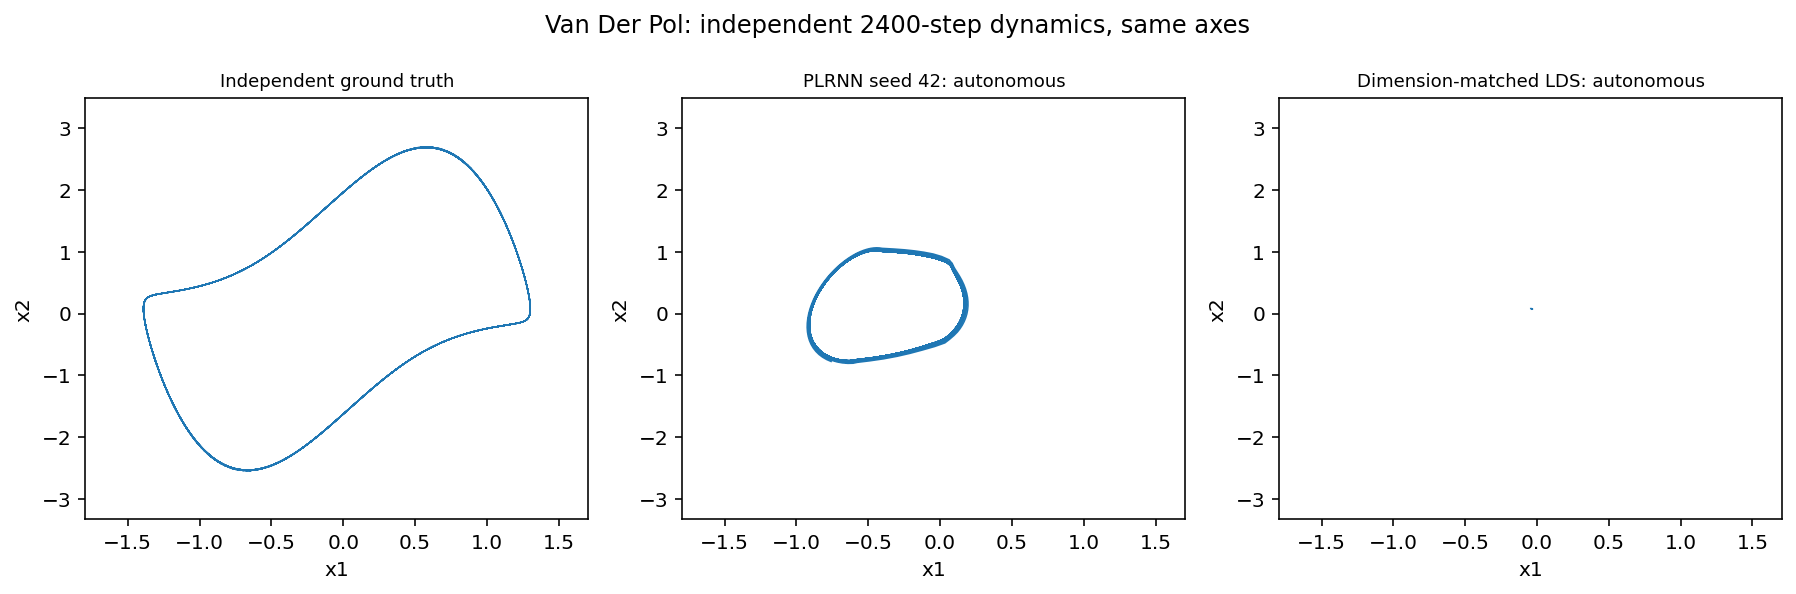

Long-term autonomous trajectories: lorenz


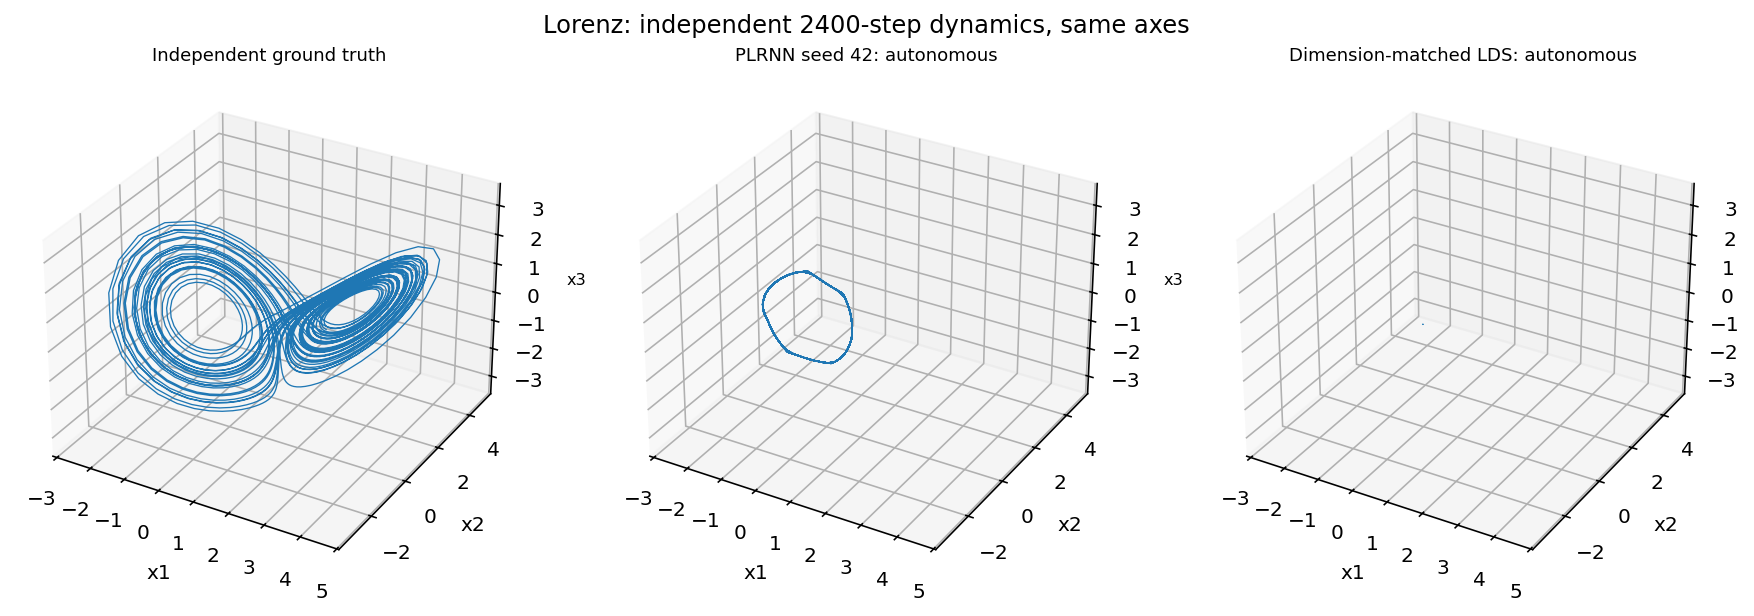

In [3]:
for system in ('van_der_pol', 'lorenz'):
    print('Long-term autonomous trajectories:', system)
    display(Image(filename=str(FIGS / f"phase4_{system}_long_rollout.png")))


### Interpretation

**Van der Pol:** The reference has a stable nonlinear limit cycle. Several PLRNN trajectories preserve a periodic orbit, but it is noticeably distorted and sometimes collapses. The matched LDS converges to a fixed point.  
**Lorenz:** Although the PLRNN performs better in the distributional metric than the matched LDS, its autonomous attractor is a simplified closed orbit rather than the original two-wing butterfly. **It does not reproduce Lorenz chaos.**

JSD across different systems is not directly a measure of which system is intrinsically easier: the dimensionality and occupancy distributions differ.

## 4. Effect of model seed and initial state

We retain every model attempt, including instability. A good looking result should not be selected **after evaluating on held-out data**, since that would bias the stated test performance.

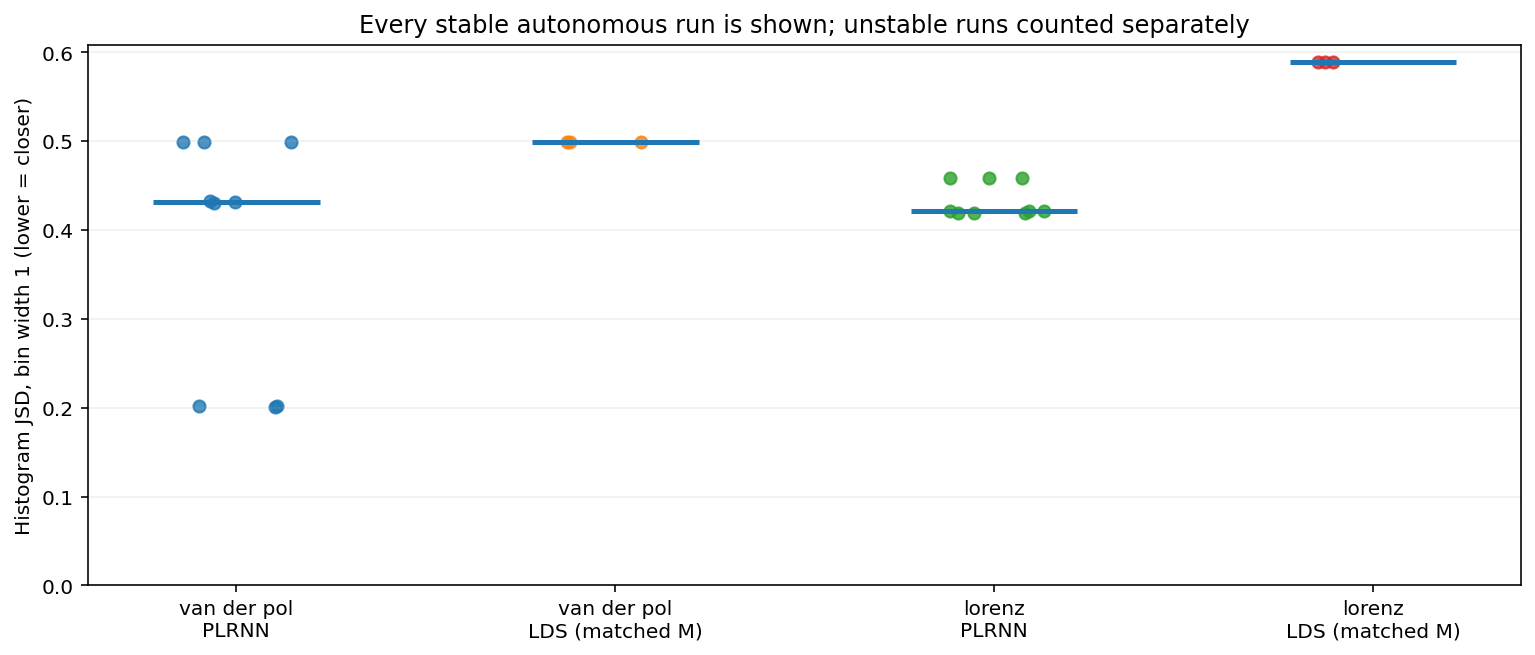

van_der_pol: PLRNN seed 42, JSDs for training-state starts: [0.431, 0.431, 0.432]
van_der_pol: PLRNN seed 7, JSDs for training-state starts: [0.5, 0.5, 0.5]
van_der_pol: PLRNN seed 21, JSDs for training-state starts: [0.202, 0.202, 0.201]
lorenz: PLRNN seed 42, JSDs for training-state starts: [0.458, 0.458, 0.458]
lorenz: PLRNN seed 7, JSDs for training-state starts: [0.42, 0.42, 0.42]
lorenz: PLRNN seed 21, JSDs for training-state starts: [0.422, 0.422, 0.422]


In [4]:
display(Image(filename=str(FIGS / 'phase4_multiseed_js.png')))
for system in ('van_der_pol','lorenz'):
    detail=json.loads((METRICS / f'phase4_{system}_runs.json').read_text(encoding='utf-8'))
    grouped={}
    for run in detail['plrnn']['runs']:
        grouped.setdefault(run['seed'],[]).append(run)
    for seed,runs in grouped.items():
        vals=[round(x['scores']['js_width_1.0'],3) if x['status']=='ok' else 'unstable' for x in runs]
        print(f'{system}: PLRNN seed {seed}, JSDs for training-state starts: {vals}')


## 5. Exploratory sensitivity to observation noise

The physical benchmark trajectory is held constant; only Gaussian measurement noise changes. For a noise ratio $s$, the standard deviation in observation channel $j$ is $s$ times the clean *training* standard deviation. The experiment repeats training with one fixed seed per noise level.

Higher noise is expected to complicate latent state inference; this is an exploratory trend only, not a statistically confirmed effect.

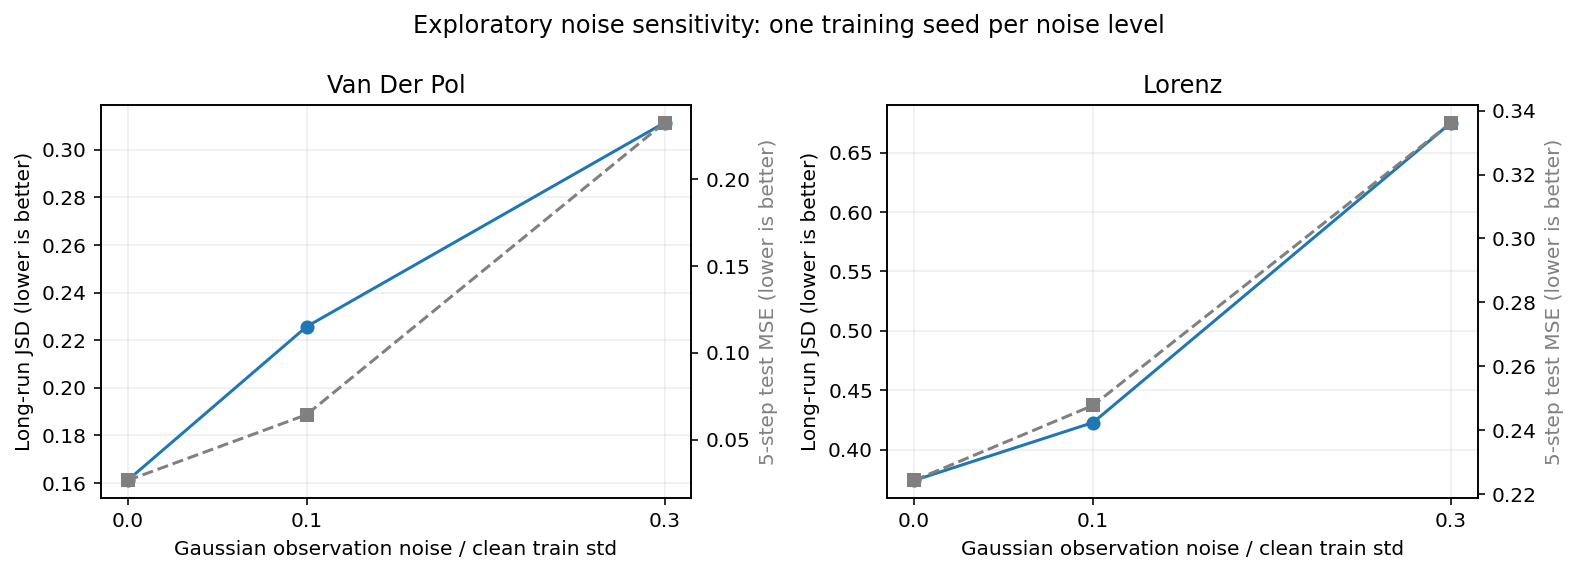

System            Noise        JSD      MSE h=5
van_der_pol         0.0     0.1611       0.0265
van_der_pol         0.1     0.2257       0.0644
van_der_pol         0.3     0.3114       0.2327
lorenz              0.0     0.3740       0.2244
lorenz              0.1     0.4228       0.2478
lorenz              0.3     0.6753       0.3362


In [5]:
display(Image(filename=str(FIGS / 'phase4_noise_ablation.png')))
print(f"{'System':<16} {'Noise':>6} {'JSD':>10} {'MSE h=5':>12}")
for r in summary['noise_ablation']:
    js='unstable' if r['js_width_1.0'] is None else f"{r['js_width_1.0']:.4f}"
    print(f"{r['system']:<16} {r['noise_std']:>6.1f} {js:>10} {r['forecast_mse_h5']:>12.4f}")


## 6. Finite-time Lyapunov and oscillation diagnostics

For a deterministic PLRNN, the local Jacobian is

$$
J_t=A+W\operatorname{diag}\big(\mathbb{I}[\mathbf z_t>0]\big).
$$

Repeatedly normalizing a tangent vector gives an approximation of the largest finite-time Lyapunov exponent,

$$
\widehat\lambda_{\max}=\frac{1}{T\,\Delta t}\sum_{t=1}^{T}\log\|J_t\mathbf v_t\|_2.
$$

For Lorenz, a **positive** largest exponent is a signature of local exponential sensitivity, but a finite-length estimate is not a mathematical proof of chaos. For van der Pol, the dominant frequency and spectral overlap provide additional checks. We do not substitute these indicators for a full dynamical-systems identification.

In [6]:
for system in ('van_der_pol','lorenz'):
    d=summary['systems'][system]
    print(system)
    if d['reference_lyapunov'] is not None:
        print('  approximate Lorenz reference finite-time exponent:', round(d['reference_lyapunov'],4))
    for model in ('plrnn','lds_matched'):
        s=d[model]['finite_time_lyapunov']
        print(' ',model,'finite-time exponent median:',s['median'])


van_der_pol
  plrnn finite-time exponent median: -0.015523111063863502
  lds_matched finite-time exponent median: -0.23503840780051585
lorenz
  approximate Lorenz reference finite-time exponent: 1.229
  plrnn finite-time exponent median: -0.009569750128504197
  lds_matched finite-time exponent median: -1.6286905856491454


## 7. Conclusions and limitations

1. **Short-horizon prediction is not evidence of long-term nonlinear-system recovery.** The PLRNN may forecast well while generating the wrong autonomous attractor.
2. The PLRNN improves upon the dimension-matched LDS in long-run histogram JSD for the reported configurations, yet is far from a faithful Lorenz reconstruction.
3. Some PLRNN van der Pol rollouts form an approximate cycle, while others decay; both **model seed and latent initial state** matter.
4. In the single-seed noise ablation, both MSE and long-run distribution discrepancy increase with measurement noise. **We cannot infer statistical significance from one training seed.**
5. **Model limitation:** this is the simplified alternating **MAP** implementation from Phase 3, not Koppe et al.'s exact Laplace-EM algorithm. The original paper's normalized KL and fMRI HRF observation model are not implemented here.

### Suggested next experiment

Use **train-only validation** to tune dynamic regularization or implement a more faithful posterior-inference scheme, then retest on a genuinely held-out trajectory. Do not use the Phase-4 test-based results to choose hyperparameters and report the same test sample as unbiased evidence.